# Time Series Aggregation: Typical Days

All notebooks so far have optimized the model with **8 typical days** per investment period instead of all 365 days. This notebook shows what happens in this step and how to choose its settings:

| Topic | Parameters and functions |
|---|---|
| Clustering the days into typical days | `esM.aggregateTemporally(n_clusters=...)`, `storeTSAinstance` |
| How many typical days are needed? | comparing results for different `n_clusters` |
| Fewer time steps per typical day | `segments` with `fn.SegmentConfig` |
| Keeping extreme days, e.g. the calmest day | `extremes` with `fn.ExtremeConfig` |

## 1. Why aggregate?

The model of the basic tutorial has 8760 hours, two regions and three investment periods. Every hour needs its own variables for the operation of every component. Optimized with all 8760 hours, it took about 8.5 minutes on a laptop with Gurobi. With 8 typical days, it takes a few seconds. Larger models, with more regions, technologies and periods, are often not solvable at all without aggregation.

The time series aggregation, done by the package [tsam](https://github.com/FZJ-IEK3-VSA/tsam), works like this:

1. The year is cut into **periods** of 24 hours, i.e. into its 365 days.
2. Similar days are grouped into **clusters**, based on all time series of the model together: demand, capacity factors, prices. Each cluster is represented by one **typical day**.
3. Every typical day gets a **weight**: the number of days it represents. The yearly operation and costs are computed with these weights.
4. The **order** of the days is kept: FINE knows which typical day stands for each of the 365 days. Storages use this to carry their filling level from one day to the next, so that they can still shift energy between seasons (see the [Storages notebook](14_storages.ipynb)).

Each investment period is aggregated separately, so the typical days of 2020 and 2040 can differ.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
from tutorialHelpers import COLORS, buildBasicTutorialModel, readData

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

## 2. The typical days

`storeTSAinstance=True` keeps the result of tsam in `esM.tsaInstance` (for the last investment period, here 2040), so that we can look at it. `cluster_counts` tells how many days each typical day represents:

In [2]:
esM = buildBasicTutorialModel()
esM.aggregateTemporally(n_clusters=8, segments=None, storeTSAinstance=True)

tsaResult8 = esM.tsaInstance  # kept for a comparison in section 5
pd.Series(tsaResult8.cluster_counts, name="Number of days").to_frame().T

,0,1,2,3,4,5,6,7
Number of days,26.0,47.0,31.0,58.0,69.0,42.0,55.0,37.0


`reconstructed` holds the time series as the optimization sees them: every day of the year replaced by its typical day. The columns are named after the component, the parameter and the region. Here are the wind capacity factors in the north during the two weeks of the basic tutorial, original and aggregated:

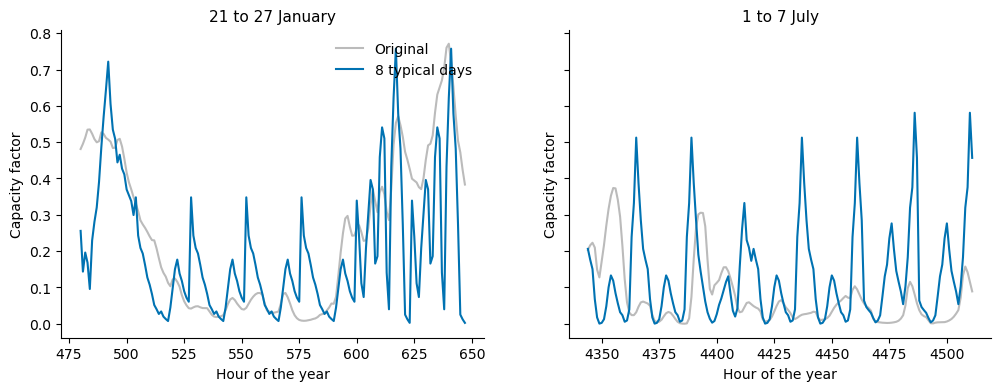

In [3]:
windCapacityFactor = readData("windCapacityFactor.csv")
reconstructed = esM.tsaInstance.reconstructed["Wind turbines_operationRateMax_north"]
weeks = {"21 to 27 January": range(480, 648), "1 to 7 July": range(4344, 4512)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, hours) in zip(axes, weeks.items()):
    ax.plot(
        hours, windCapacityFactor.loc[hours, "north"], color="#BBBBBB", label="Original"
    )
    ax.plot(
        hours,
        reconstructed.iloc[list(hours)],
        color=COLORS["Wind turbines"],
        label="8 typical days",
    )
    ax.set(title=title, xlabel="Hour of the year", ylabel="Capacity factor")
axes[0].legend(loc="upper right")

The typical days follow the rough course of the weather: windy days remain windy and calm days remain calm. The course within a day, however, can differ considerably from the original, as on the calm days in July. With only 8 typical days, many different days have to share one typical day.

## 3. How many typical days are needed?

More typical days describe the year better but make the problem larger. We optimize the model with 4, 8, 16 and 32 typical days and compare the total cost, some capacities in 2040 and the time it takes. `esM.solverSpecs["runtime"]` is the time FINE needed to build and solve the optimization problem in seconds.

In [4]:
def capacities2040(esM):
    """Capacities of some components in 2040, both regions added up."""
    result = {}
    for modelingClass, component in [
        ("SourceSinkModel", "Wind turbines"),
        ("SourceSinkModel", "PV"),
        ("ConversionModel", "Gas power plants"),
        ("StorageModel", "Batteries"),
    ]:
        summary = esM.getOptimizationSummary(modelingClass, outputLevel=1, ip=2040)
        result[component] = summary.loc[(component, "capacity")].iloc[0].sum()
    return result

In [5]:
comparison = {}
for nTypicalDays in [4, 8, 16, 32]:
    esM = buildBasicTutorialModel()
    esM.aggregateTemporally(n_clusters=nTypicalDays, segments=None)
    esM.optimize(timeSeriesAggregation=True)
    comparison[f"{nTypicalDays} typical days"] = {
        "Total cost [billion Euro]": esM.objectiveValue / 1000,
        "Run time [s]": esM.solverSpecs["runtime"],
        **capacities2040(esM),
    }

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (352 outputs left out)

Extra simplex iterations after uncrush: 11


   13679    6.6618675e+05   0.000000e+00   0.000000e+00      5s


Solved in 13679 iterations and 4.89 seconds (4.11 work units)


Optimal objective  6.661867501e+05


In [6]:
comparison = pd.DataFrame(comparison).T.astype(float)
comparison.round(1)

,Total cost [billion Euro],Run time [s],Wind turbines,PV,Gas power plants,Batteries
4 typical days,590.0,6.2,382.7,189.7,57.6,438.6
8 typical days,597.4,7.3,383.2,189.7,63.1,501.3
16 typical days,624.7,11.6,413.2,189.7,65.8,817.7
32 typical days,666.2,20.5,413.2,189.7,63.7,1797.1


The more typical days, the higher the total cost: from 590 billion Euro with 4 typical days to 666 billion Euro with 32. Wind turbines and PV hardly change (with 16 and more typical days, the whole wind potential is used). The batteries change most: from about 440 GWh to about 1800 GWh. Typical days average out a part of the variation from hour to hour and from day to day, so with few typical days, the system appears easier to balance than it is.

The total cost of the same model optimized with all 8760 hours is about 663 billion Euro (computed once; it takes several minutes). The plot shows how the results approach it:

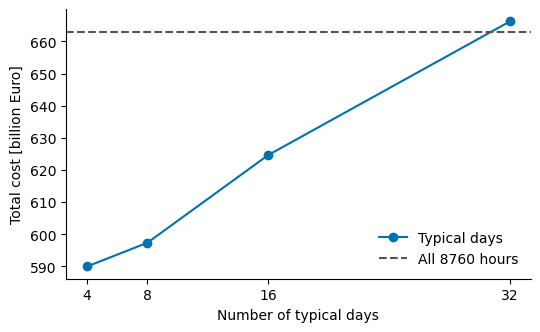

In [7]:
fullResolutionCost = 663  # billion Euro, all 8760 hours (computed once)

fig, ax = plt.subplots(figsize=(6, 3.5))
nTypicalDays = [int(name.split()[0]) for name in comparison.index]
ax.plot(
    nTypicalDays,
    comparison["Total cost [billion Euro]"],
    marker="o",
    color="#0072B2",
    label="Typical days",
)
ax.axhline(fullResolutionCost, color="#555555", linestyle="--", label="All 8760 hours")
ax.set(
    xticks=nTypicalDays,
    xlabel="Number of typical days",
    ylabel="Total cost [billion Euro]",
)
ax.legend(loc="lower right")

The cost does not approach the result with all hours from one side: with 32 typical days, it is even slightly above it. The 8 typical days used in these notebooks underestimate the total cost by about 10 %. This is fine for learning how FINE works, but not for a study.

## 4. Fewer time steps per day with `segments`

Instead of more typical days, each typical day can also be described by fewer, longer time steps. With **segmentation**, tsam merges consecutive hours with similar values into **segments** of different length: a calm night may become one long segment, while the hours around sunrise stay short. `segments=fn.SegmentConfig(n_segments=6)` describes each typical day by 6 segments instead of 24 hours. If `segments` is not given, `aggregateTemporally` uses 12 segments per day; that is why all notebooks set `segments=None` to keep the hours.

This makes it possible to use more typical days for about the same problem size: 32 typical days with 6 segments have as many time steps as 8 typical days with 24 hours.

In [8]:
esM = buildBasicTutorialModel()
esM.aggregateTemporally(n_clusters=32, segments=fn.SegmentConfig(n_segments=6))
esM.optimize(timeSeriesAggregation=True)
comparison.loc["32 typical days, 6 segments"] = {
    "Total cost [billion Euro]": esM.objectiveValue / 1000,
    "Run time [s]": esM.solverSpecs["runtime"],
    **capacities2040(esM),
}

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (90 outputs left out)

Solved with barrier


    3416    6.5840914e+05   0.000000e+00   0.000000e+00      2s


Solved in 3416 iterations and 2.45 seconds (1.73 work units)


Optimal objective  6.584091357e+05


In [9]:
comparison.round(1)

,Total cost [billion Euro],Run time [s],Wind turbines,PV,Gas power plants,Batteries
4 typical days,590.0,6.2,382.7,189.7,57.6,438.6
8 typical days,597.4,7.3,383.2,189.7,63.1,501.3
16 typical days,624.7,11.6,413.2,189.7,65.8,817.7
32 typical days,666.2,20.5,413.2,189.7,63.7,1797.1
"32 typical days, 6 segments",658.4,10.9,413.2,189.7,64.6,1703.5


With 32 typical days of 6 segments, the total cost (658 billion Euro) and the capacities are close to those with 32 typical days of 24 hours, although the problem has only as many time steps as with 8 typical days of 24 hours. The run time, however, was not shorter here than with 32 hourly typical days: fewer time steps do not always mean a faster solution.

## 5. Keeping extreme days with `extremes`

Clustering averages similar days, so the most extreme days disappear: the typical day that represents the calmest day of the year also represents days with more wind. A system optimized with typical days may therefore be too small for the hardest days. `extremes=fn.ExtremeConfig(...)` adds extreme days to the typical days. With `min_period`, the day with the lowest daily sum of a time series becomes an additional typical day of its own; the time series are named as in `reconstructed` above. (`max_period`, `min_value` and `max_value` work the same way, e.g. `max_value` for the day with the highest demand peak.)

For a system with a lot of wind power, the calmest days matter, so we keep the calmest day of each region:

In [10]:
calmestDays = fn.ExtremeConfig(
    min_period=[
        "Wind turbines_operationRateMax_north",
        "Wind turbines_operationRateMax_south",
    ]
)
esM = buildBasicTutorialModel()
esM.aggregateTemporally(
    n_clusters=8, segments=None, extremes=calmestDays, storeTSAinstance=True
)
esM.optimize(timeSeriesAggregation=True)
comparison.loc["8 typical days + calmest days"] = {
    "Total cost [billion Euro]": esM.objectiveValue / 1000,
    "Run time [s]": esM.solverSpecs["runtime"],
    **capacities2040(esM),
}

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (79 outputs left out)

Solved with barrier


    2840    5.9987032e+05   0.000000e+00   0.000000e+00      1s


Solved in 2840 iterations and 1.16 seconds (1.42 work units)


Optimal objective  5.998703150e+05


The mean wind capacity factor in the north on the calmest day, in the original data and as the optimization sees it:

In [11]:
def lowestDailyMean(hourlyValues):
    """Lowest mean of the 24 hours of a day over the 365 days of the year."""
    return hourlyValues.to_numpy().reshape(365, 24).mean(axis=1).min()


column = "Wind turbines_operationRateMax_north"
pd.Series(
    {
        "Original": lowestDailyMean(windCapacityFactor["north"]),
        "8 typical days": lowestDailyMean(tsaResult8.reconstructed[column]),
        "8 typical days + calmest days": lowestDailyMean(
            esM.tsaInstance.reconstructed[column]
        ),
    },
    name="Wind capacity factor on the calmest day (north)",
).round(3)

Original                         0.004
8 typical days                   0.108
8 typical days + calmest days    0.004
Name: Wind capacity factor on the calmest day (north), dtype: float64

In [12]:
comparison.round(1)

,Total cost [billion Euro],Run time [s],Wind turbines,PV,Gas power plants,Batteries
4 typical days,590.0,6.2,382.7,189.7,57.6,438.6
8 typical days,597.4,7.3,383.2,189.7,63.1,501.3
16 typical days,624.7,11.6,413.2,189.7,65.8,817.7
32 typical days,666.2,20.5,413.2,189.7,63.7,1797.1
"32 typical days, 6 segments",658.4,10.9,413.2,189.7,64.6,1703.5
8 typical days + calmest days,599.9,8.9,390.0,189.7,63.0,498.5


Without the extreme days, the calmest day the model sees is much windier than the real one. With them, the real calmest day is part of the optimization. In this model, this changes little: the total cost rises by about 2.5 billion Euro, and the gas power plants are already large enough to cover the calm days. Whether extreme days matter depends on the model; checking it costs only one more run.

## Recommendations

- Start with few typical days while building a model, so that every run is fast.
- For results that you want to interpret, check that they hardly change with more typical days, as in section 3.
- Add extreme days for the time series that size the system, e.g. the peak demand or a calm week.
- Seasonal storage needs the order of the days, which FINE keeps by default. Storages that only shift energy within a day can be modeled with `isPeriodicalStorage=True`.

## Things to try

- Use 64 typical days. How close does the total cost get to the result with all hours?
- Keep the day with the highest electricity demand of each region (`max_value` with the columns `"Electricity demand_operationRateFix_north"` and `"Electricity demand_operationRateFix_south"`).

The next notebook, [Solver Settings and Saving](32_solver_settings_and_saving.ipynb), shows how to control the solver and how to save an optimized model.